=== PUNTO 1: PERCEPTRÓN ===
Parámetros Actualizados -> w: [1.  0.5], b: 0.5, Margen: 3.0

=== PUNTO 2: k-NN (make_moons) ===
k= 1 | Train Accuracy: 100.00% | Test Accuracy: 93.33%
k= 5 | Train Accuracy: 95.71% | Test Accuracy: 95.56%
k=15 | Train Accuracy: 95.71% | Test Accuracy: 93.33%


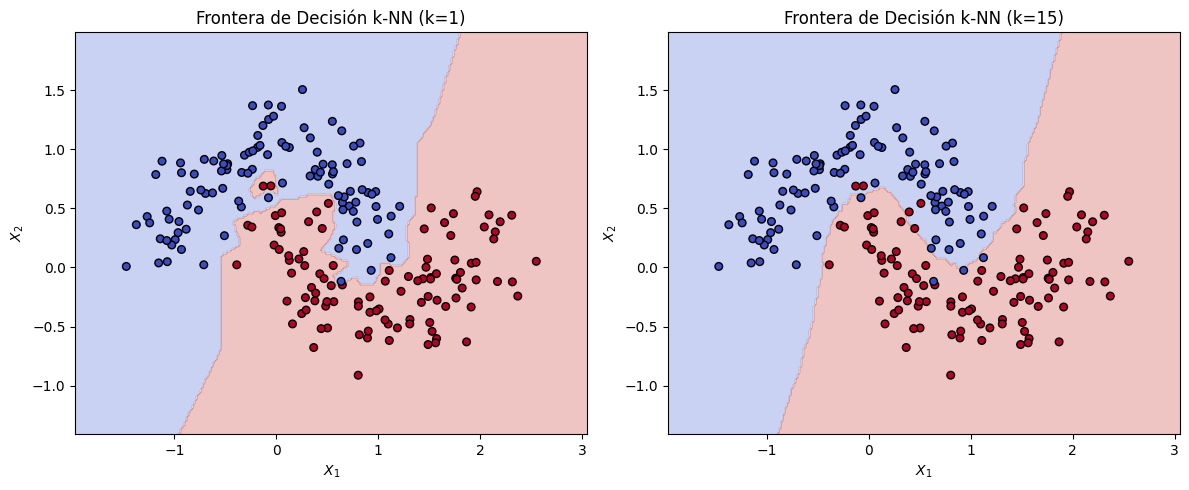


=== PUNTO 3: MÉTRICAS DE EVALUACIÓN ===
Matriz de Confusión:
[[3 1]
 [2 4]]
Accuracy : 0.7000
Precision: 0.8000
Recall   : 0.6667
F1-Score : 0.7273


In [1]:
import matplotlib.pyplot as plt
import numpy as np
from sklearn.datasets import make_moons
from sklearn.metrics import (
    accuracy_score,
    confusion_matrix,
    f1_score,
    precision_score,
    recall_score,
)
from sklearn.model_selection import train_test_split
from sklearn.neighbors import KNeighborsClassifier

# Set global random seed
SEED = 42

# ==========================================
# PUNTO 1: Verificación Algoritmo Perceptrón
# ==========================================
print("=== PUNTO 1: PERCEPTRÓN ===")
w0 = np.array([0.0, 0.0])
b0 = 0.0
eta = 0.5
x_13 = np.array([2.0, 1.0])
y_13 = +1

# Predicción inicial
val_pred = np.dot(w0, x_13) + b0
y_hat = +1 if val_pred > 0 else -1

if y_hat != y_13:
    w_new = w0 + eta * y_13 * x_13
    b_new = b0 + eta * y_13
    m_new = y_13 * (np.dot(w_new, x_13) + b_new)
    print(f"Parámetros Actualizados -> w: {w_new}, b: {b_new}, Margen: {m_new}")

# ==========================================
# PUNTO 2: k-NN con make_moons
# ==========================================
print("\n=== PUNTO 2: k-NN (make_moons) ===")
X, y = make_moons(n_samples=300, noise=0.20, random_state=SEED)
X_train, X_test, y_train, y_test = train_test_split(
    X, y, test_size=0.30, random_state=SEED, stratify=y
)

k_values = [1, 5, 15]
models = {}

for k in k_values:
    knn = KNeighborsClassifier(n_neighbors=k)
    knn.fit(X_train, y_train)
    acc_train = knn.score(X_train, y_train)
    acc_test = knn.score(X_test, y_test)
    models[k] = knn
    print(
        f"k={k:2d} | Train Accuracy: {acc_train*100:.2f}% | Test Accuracy: {acc_test*100:.2f}%"
    )

# Graficar Regiones de Decisión para k=1 y k=15
fig, axes = plt.subplots(1, 2, figsize=(12, 5))
h = 0.02
x_min, x_max = X[:, 0].min() - 0.5, X[:, 0].max() + 0.5
y_min, y_max = X[:, 1].min() - 0.5, X[:, 1].max() + 0.5
xx, yy = np.meshgrid(np.arange(x_min, x_max, h), np.arange(y_min, y_max, h))

for idx, k in enumerate([1, 15]):
    Z = models[k].predict(np.c_[xx.ravel(), yy.ravel()])
    Z = Z.reshape(xx.shape)
    axes[idx].contourf(xx, yy, Z, alpha=0.3, cmap=plt.cm.coolwarm)
    axes[idx].scatter(
        X_train[:, 0],
        X_train[:, 1],
        c=y_train,
        cmap=plt.cm.coolwarm,
        edgecolors="k",
        s=30,
    )
    axes[idx].set_title(f"Frontera de Decisión k-NN (k={k})")
    axes[idx].set_xlabel("$X_1$")
    axes[idx].set_ylabel("$X_2$")

plt.tight_layout()
plt.show()

# ==========================================
# PUNTO 3: Evaluación de Clasificador Binario
# ==========================================
print("\n=== PUNTO 3: MÉTRICAS DE EVALUACIÓN ===")
y_true = np.array([0, 0, 0, 0, 1, 1, 1, 1, 1, 1])
y_pred = np.array([0, 1, 0, 0, 1, 0, 1, 1, 0, 1])

cm = confusion_matrix(y_true, y_pred)
acc = accuracy_score(y_true, y_pred)
prec = precision_score(y_true, y_pred)
rec = recall_score(y_true, y_pred)
f1 = f1_score(y_true, y_pred)

print("Matriz de Confusión:")
print(cm)
print(f"Accuracy : {acc:.4f}")
print(f"Precision: {prec:.4f}")
print(f"Recall   : {rec:.4f}")
print(f"F1-Score : {f1:.4f}")